In [201]:
import math
import torch
from torch import nn, optim, linalg
import matplotlib.pyplot as plt

from utils import *

# Optimisation d'une matrice post-activation

Selon ce papier (https://arxiv.org/abs/2512.04299), la descente spectrale
fonctionne mieux pour optimiser des matrices post-activation. On tente de
reproduire l'exemple de la figure 3 de l'article. Notez qu'il y a une erreur
dans le papier sur la taille de X, c'est 50×400.

L'algorithme du papier utilise l'update $Wₖ₊₁ = Wₖ - γ ‖∇F(Wₖ)‖_* ~ polar(∇F(Wₖ))$,
l'implémentation de pytorch n'utilise pas cette multiplication par la norme
nucléaire et j'ai la flemme de l'implémenter, donc on fait sans.

On pose $X ∈ ℝ^{50 × 400}$, $W₁ ∈ ℝ^{100 × 50}$, $W_♯ ∈ ℝ^{100 × 100}$ dont les
entrées sont tirées respectivement selon les lois $𝒩(0, 1)$, $𝒩(0, 1/50)$,
$𝒩(0, 1/100)$. On pose alors $A = ReLU(W₁ X)$ et $Y = W_♯ A$. On cherche à
résoudre le problème

$$\min_{W ∈ ℝ^{100 × 100}} F(W) = \frac{1}{2} ‖W A - Y‖_F^2$$

In [202]:
def make_data(in_dim, hidden_dim, out_dim, activation=nn.ReLU()):
    X = torch.randn(hidden_dim, in_dim)
    W1 = torch.randn(out_dim, hidden_dim) / math.sqrt(hidden)
    A = activation(W1 @ X)

    W_sharp = torch.randn(out_dim, out_dim) / math.sqrt(out_dim)
    Y = W_sharp @ A

    return A, Y

In [203]:
class Model(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        weight = torch.zeros((out_dim, out_dim))
        self.weight = nn.Parameter(weight)

    def forward(self, A):
        return self.weight @ A

In [204]:
def train_model(A, Y, model, optimizer, epoch=1000):
    n = A.shape[1]
    losses = []
    for _ in range(epoch):
        loss = (.5/n) * linalg.norm(model(A) - Y, ord='fro')**2
        losses.append(loss.item())
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    return losses

In [205]:
in_dim = 400
hidden = 50
out_dim = 100

A, Y = make_data(in_dim, hidden, out_dim)

In [206]:
names = ("GD", "Spectral GD")
models = [Model(out_dim) for _ in names]

# Pas donnés par le papier, on multiplie seulement celui de Spectral GD par 0.4
optimizers = [
    optim.SGD(   models[0].parameters(), lr=1.9 * in_dim/linalg.norm(A, ord=2)**2),
    spectral_GD(*models[1].parameters(), lr=.4 * in_dim/linalg.norm(A, ord='fro')**2)
]

losses = [train_model(A, Y, model, optimizer) for model, optimizer in zip(models, optimizers)]

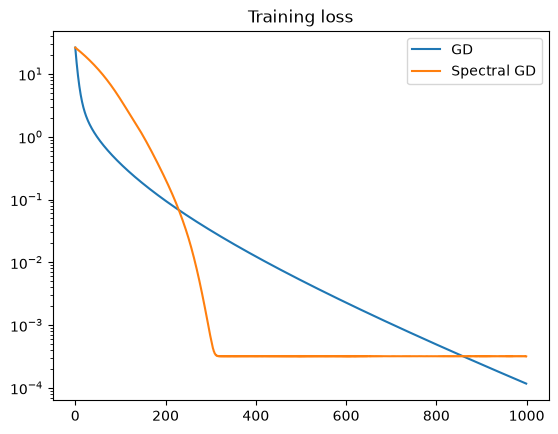

In [207]:
fig, ax = plt.subplots()
ax.set_title("Training loss")
ax.set_yscale('log')
for name, loss in zip(names, losses):
    ax.plot(loss, label=name)
ax.legend()

plt.show()